# Labrapport TFY4125 Fysikk Vår 2024

Navn:   Ingrid Bårdseth,
        Varvara Chinaeva,
		Anders Holtan,
		Theodor Kvalsvik Lauritzen,
		Mille Åsbø <br>
Institutt for Fysikk, NTNU <br>
Dato: 


## Sammendrag
*Skriv en kort oppsummering av labprosjektet. Skriv denne delen helt til slutt. Beskriv eksperimentet og de numeriske beregningene. Fokuser på resultatene. Oppgi midlere tap i mekanisk energi med tilhørende usikkerhet (standardfeil). Bruk maksimalt 5 setninger.*

## Ren rulling på krum bane - teoretisk grunnlag
Figuren nedenfor viser ei kule som ruller på et krumt underlag, med krumning henholdsvis oppover (øverst) og nedover (nederst). I figuren angis tyngdekraften $Mg$ og de to komponentene av kontaktkraften fra underlaget på kula, henholdsvis normalkraften $N$ og friksjonskraften $f$. Dessuten er både hastigheten $v$, baneakselerasjonen $a$ og sentripetalakselerasjonen $a_\perp$ illustrert. Ved perfekt ren rulling - uten andre former for friksjon enn den statiske friksjonen $f$ som virker i kontaktpunktet mellom kula og underlaget - er kulas mekaniske energi bevart. Da er kulas hastighet entydig bestemt av endringen $y$ i den vertikale posisjonen til kulas massesenter via
$$\frac{1}{2} (1+c) Mv^2 = Mgy,$$
idet vi antar at kula starter med hastighet $v=0$ i høyden $y=0$. Dersom kula er kompakt med uniform massefordeling, er $c=2/5$, slik at 
$$v(y) = \sqrt{\frac{10}{7}gy}.$$
Kulas baneakselerasjon blir dermed 
$$a = \frac{dv}{dt} = \frac{dv}{dy}\,\frac{dy}{dt} = \sqrt{\frac{5g}{14y}}\,v_y.$$
Her er $v_y = v \sin\beta = \sqrt{10gy/7}\sin\beta$ slik at
$$a = -\frac{5g\sin\beta}{7}.$$
Her er $\beta$ banens lokale helningsvinkel, knyttet til banens geometriske form $y(x)$ ved at
$$\frac{dy}{dx} = \tan\beta.$$
Vi innser nå at de to siste ligningene har konsistente fortegn: Kula ruller åpenbart saktere og saktere i motbakke.
Da er både $\sin\beta$ og $\tan\beta$ positive størrelser dersom $\beta > 0$.
Friksjonskraften kan nå bestemmes ved hjelp av Newtons 2. lov:
$$f - Mg\sin\beta = Ma = -\frac{5Mg\sin\beta}{7},$$
dvs
$$f = \frac{2Mg\sin\beta}{7}.$$
Retningen på $f$ må være konsistent med at vinkelfarten øker i nedoverbakke og minker i oppoverbakke. Av den grunn peker $f$ alltid oppover langs banen. Vi ser at fortegnet stemmer: Motbakke og $\beta > 0$ gir $f>0$, dvs framover og oppover. Utforbakke og $\beta < 0$ gir $f<0$, dvs bakover og oppover. <br>
Endelig kan normalkraften bestemmes ved hjelp av Newtons 2. lov i retning normalt på banen:
$$N - Mg\cos\beta = M a_\perp = M v^2/R = Mv^2K.$$
Her er $R$ banens krumningsradius og $K$ krumningen, gitt ved
$$K = \frac{y''}{[1+(y')^2]^{3/2}},$$
med $y' = dy/dx$ og $y'' = d^2y/dx^2$. Normalkraften har selvsagt retning oppover til enhver tid (dvs med positiv $y$-komponent). Sentripetalakselerasjonen har retning inn mot sentrum av den tenkte sirkelen med radius $R$. Når banen krummer oppover, er $y'' > 0$ og $K > 0$ i siste ligning. Det betyr at fortegnet stemmer: $N$ er større enn tyngdens normalkomponent $Mg\cos\beta$ når banen krummer oppover. Og omvendt: Når banen krummer nedover, er $y'' < 0$ og $K < 0$ i siste ligning. Det gir en normalkraft $N$ som er mindre enn tyngdens normalkomponent. Av erfaring vet vi at dette stemmer: Kjører vi fort nok på ski over en 'kul', kan vi helt miste kontakten med underlaget, dvs $N=0$. Her skal vi sørge for at baneformen $y(x)$ er slik at den rullende kula hele tiden har god kontakt med underlaget.

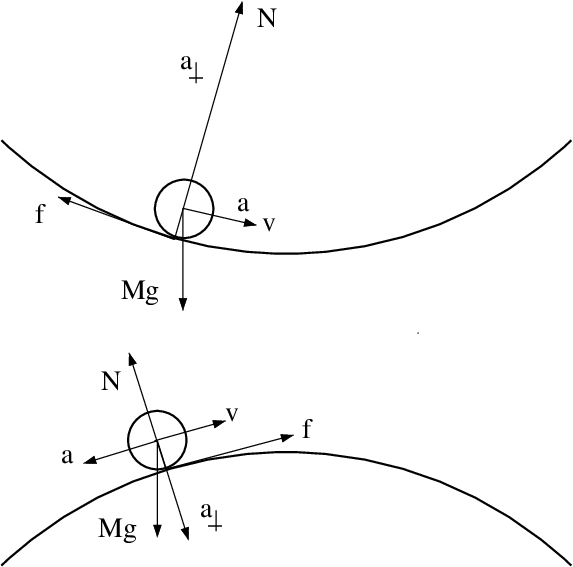

In [1]:
from IPython import display
display.Image("./krefter.png", width=400)

<b>Figur 1.</b> Kule som ruller på et krumt underlag. Her er $v$ kulas fart,
$a$ er baneakselerasjon, $a_\perp$ er sentripetalakselerasjon, $Mg$ er tyngdekraft,
$f$ er friksjonskraft og $N$ er normalkraft. Banens helningsvinkel $\beta$ er vinkelen mellom
positiv $x$-akse (horisontal og mot høyre) og retningen til $v$. <br><br>

## Baneform med kubiske *splines*

Baneformen fastlegges ved hjelp av tredjegradspolynomer på de 7 intervallene mellom de 8 tilfeldig valgte skruefestehøydene, slik at både banen $y(x)$, banens deriverte $dy/dx$ og banens andrederiverte $d^2y/dx^2$ er kontinuerlige i skruefestene. Dette gjøres i Python med funksjonen CubicSpline fra SciPy-biblioteket interpolate med kommandoen

*cs = CubicSpline(xfast,yfast,bc_type='natural')*

Her er xfast og yfast tabeller (numpy arrays) med henholdsvis horisontale og vertikale koordinater for skruefestene, og med *bc_type='natural'* velges krumning lik null i de to ytterste skruefestene. Horisontal avstand mellom skruefestene er 200 mm slik at xfast = (0,0.200,...,1.400) m. Vertikale koordinater for skruefestene fastlegges ved å trekke tilfeldige tall med numpy-funksjonen random.randint.


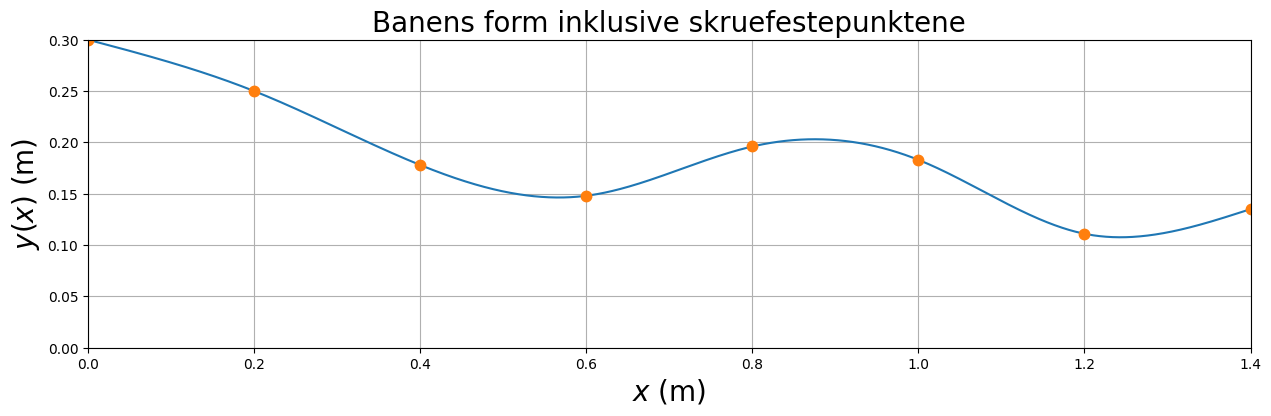

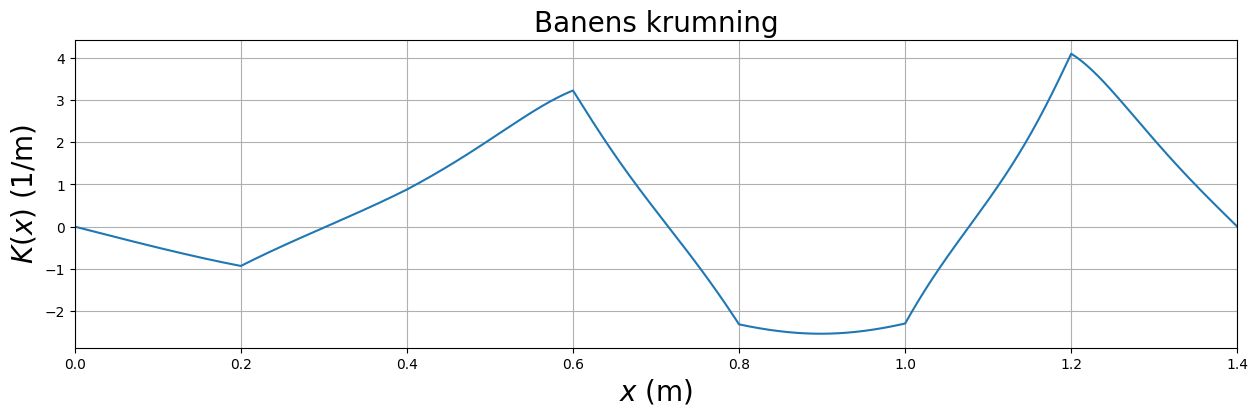

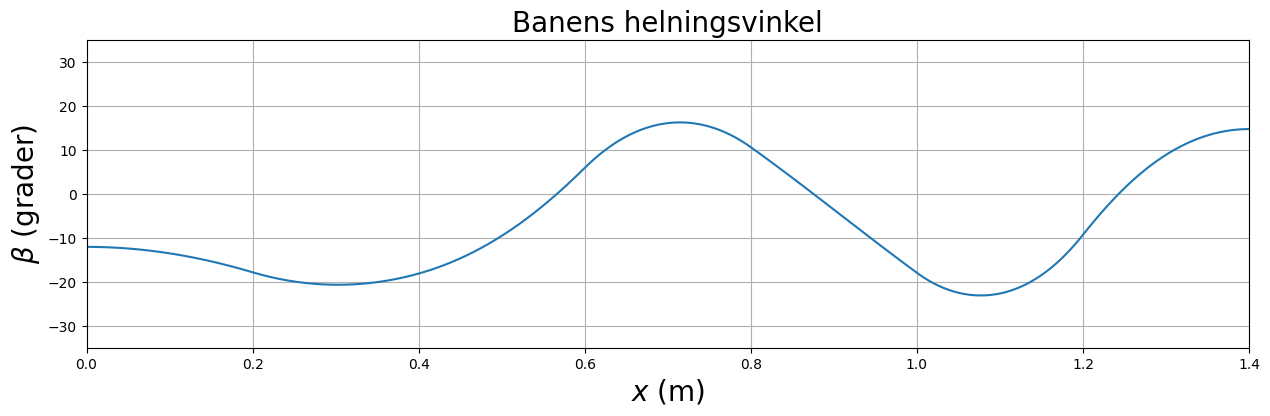

Bakketoppens høyeste punkt (m):  0.203
Banens laveste punkt (m):  0.108
Helningsvinkel i startposisjonen (grader): -12.1
Banens maksimale helningsvinkel (grader): 23.1
De 8 festepunkthøydene (m): [0.3   0.25  0.178 0.148 0.196 0.183 0.111 0.135]


In [3]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import CubicSpline

#Tallverdier. Tryggest med SI-enheter fra start til mål!
M = 0.031    #kg
g = 9.81     #m/s**2
c = 2/5
h = 0.200    #m
xfast=np.asarray([0,1,2,3,4,5,6,7])*h
xmin = 0
xmax = 1.401
dx = 0.001
x = np.arange(xmin, xmax, dx)
Nx = len(x)

#Skruehøyder:
yfast = np.zeros(8)
yfast[0] = 0.300
yfast[1] = yfast[0] - np.random.randint(40,60)/1000
yfast[2] = yfast[1] - np.random.randint(70,90)/1000
yfast[3] = yfast[2] + np.random.randint(-30,10)/1000
yfast[4] = yfast[3] + np.random.randint(30,70)/1000
yfast[5] = yfast[4] + np.random.randint(-20,20)/1000
yfast[6] = yfast[5] - np.random.randint(40,80)/1000
yfast[7] = yfast[6] + np.random.randint(-40,40)/1000

#Kjør denne cellen så mange ganger dere vil, inntil dere får en baneform dere er fornøyd med.
#Når endelig baneform er valgt:
#Sett inn skruehøydene med 3 desimaler (m) og fjern kommentarsymbolet ("#") i neste linje.
#yfast = np.asarray([0.300,,,,,,,])
yfast = np.array([0.3, 0.25, 0.178, 0.148, 0.196, 0.183, 0.111, 0.135])
#Når endelig baneform er valgt, kan dere gjerne legge inn # i starten på de 8 linjene som beregner yfast[] ovenfor

#Beregninger:
cs = CubicSpline(xfast, yfast, bc_type='natural')
#y = baneformen y(x)
y = cs(x)
#dydx = dy/dx = y'(x) (dimensjonsløs)
dydx = cs(x,1)
#d2ydx2 = y''(x) (enhet 1/m)
d2ydx2 = cs(x,2)
#K = 1/R = banens krumning (1/m)
K = d2ydx2/(1+dydx**2)**(1.5)
#beta = banens helningsvinkel (rad)
beta = np.arctan(dydx)
#betadeg = banens helningsvinkel (grader)
betadeg = beta*180/np.pi
#startvinkel = helningsvinkel i startposisjonen (grader)
startvinkel = betadeg[0]
#maksvinkel = banens maksimale helningsvinkel, i absoluttverdi (grader)
maksvinkel = np.max(np.abs(betadeg))

#Plotting av banens form y(x)
plt.figure(figsize=(15,4))
plt.plot(x,y)
plt.plot(xfast,yfast,'.',markersize=15)
plt.title('Banens form inklusive skruefestepunktene',fontsize=20)
plt.xlabel('$x$ (m)',fontsize=20)
plt.ylabel('$y(x)$ (m)',fontsize=20)
plt.ylim(0,0.300)
plt.xlim(0,1.400)
plt.grid()
plt.show()

#Plotting av banens krumning
plt.figure(figsize=(15,4))
plt.plot(x,K)
plt.title('Banens krumning',fontsize=20)
plt.xlabel('$x$ (m)',fontsize=20)
plt.ylabel('$K(x)$ (1/m)',fontsize=20)
plt.xlim(0,1.400)
plt.grid()
plt.show()


#Plotting av banens helningsvinkel
plt.figure(figsize=(15,4))
plt.plot(x,betadeg)
plt.title('Banens helningsvinkel',fontsize=20)
plt.xlabel('$x$ (m)',fontsize=20)
plt.ylabel(r'$\beta$ (grader)',fontsize=20)
plt.ylim(-35,35)
plt.xlim(0,1.400)
plt.grid()
plt.show()

y37 = y[400:1400]
y27 = y[200:1400]
y37min = np.min(y37)
y37max = np.max(y37)
y27min = np.min(y27)
y27max = np.max(y27)
print('Bakketoppens høyeste punkt (m): %6.3f' %y37max)
print('Banens laveste punkt (m): %6.3f' %y27min)
print('Helningsvinkel i startposisjonen (grader): %4.1f' %startvinkel)
print('Banens maksimale helningsvinkel (grader): %4.1f' %maksvinkel)
print('De 8 festepunkthøydene (m):', yfast)

## Numerisk beregnede fysiske størrelser
*I neste celle skal dere beregne sentrale fysiske størrelser med utgangspunkt i den valgte baneformen. Fullfør cellen med nødvendig kode slik at de ulike størrelsene beregnes og plottes i pene figurer, i samme format som figurene ovenfor. Husk enhet på alle akser. Der flere kurver vises i samme figur må det framgå hva hver enkelt kurve framstiller. Følgende størrelser skal beregnes og plottes:*
* Kulas hastighet (m/s) som funksjon av horisontal posisjon $x$ (m): 
$$v(x)=\sqrt{\frac{10g[y(0)-y(x)]}{7}}$$
* Normalkraft $N$ og friksjonskraft $f$ (N) som funksjon av $x$ (m) i samme figur: <br>
$$N = Mg\cos\beta + M v^2K$$
$$f = \frac{2Mg\sin\beta}{7}$$
* Forholdet $|f/N|$ som funksjon av $x$ (m). <br>
* Kulas hastighet $v$ (m/s) som funksjon av tid $t$ (s). <br>
* Potensiell energi, kinetisk energi og total energi (J) som funksjon av $x$ (m). <br>

*Skriv til slutt ut tallverdier for kulas rulletid (s), slutthastighet (m/s) og tilhørende total mekanisk energi (J).* 

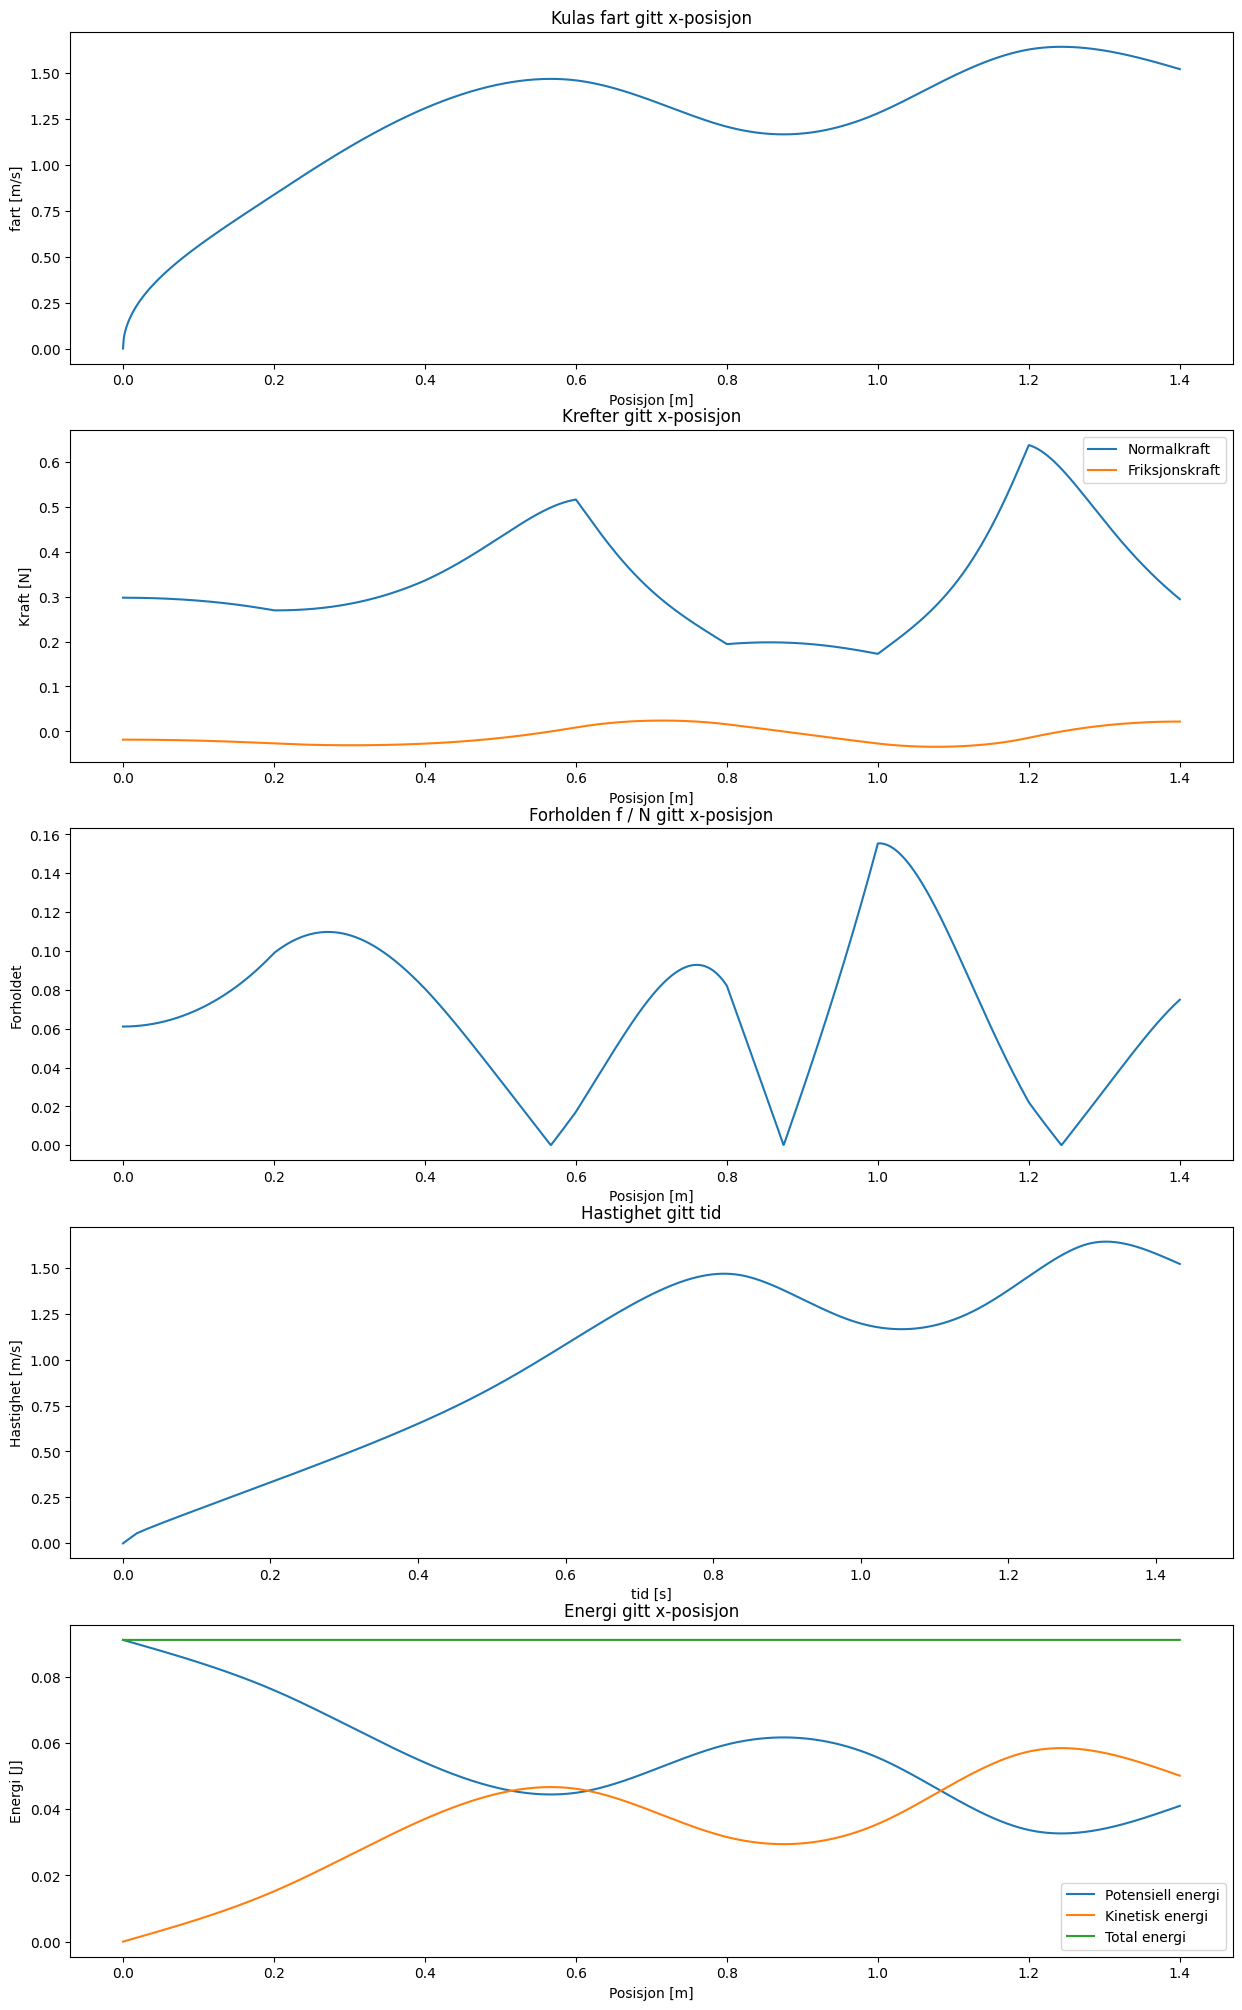

Rulletid: 1.433s
Sluttfart: 1.521m/s
Total mekanisk energi: 0.091J


In [62]:
#Numerisk beregning og plotting av de fysiske størrelsene v(x), N(x), f(x), f/N|, v(t), Epot(x), Ekin(x), Etot(x)

fig, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(5, figsize=(15, 25))

# Kulas hastighet
v = np.sqrt(10 * g * (y[0] - y) / 7)

ax1.plot(x, v)
ax1.set_title("Kulas fart gitt x-posisjon")
ax1.set_ylabel("fart [m/s]")
ax1.set_xlabel("Posisjon [m]")

# Normalkraften og friksjonskraften
N = M * g * np.cos(beta) + M * v ** 2 * K
ax2.plot(x, N, label="Normalkraft")

f = 2 * M * g * np.sin(beta) / 7
ax2.plot(x, f, label="Friksjonskraft")

ax2.set_title("Krefter gitt x-posisjon")
ax2.set_ylabel("Kraft [N]")
ax2.set_xlabel("Posisjon [m]")
ax2.legend()

# Forholdet f / N
ax3.plot(x, np.abs(f / N))
ax3.set_title("Forholden f / N gitt x-posisjon")
ax3.set_ylabel("Forholdet")
ax3.set_xlabel("Posisjon [m]")

# Hastighet gitt tid
dy = np.diff(y)
ds = np.sqrt(dx**2 + dy**2)
dt = ds / v[1:]
t = np.concatenate(([0], dt)).cumsum()

ax4.plot(t, v)
ax4.set_title("Hastighet gitt tid")
ax4.set_ylabel("Hastighet [m/s]")
ax4.set_xlabel("tid [s]")

# Energi gitt x-posisjon
Epot = M * g * y
ax5.plot(x, Epot, label="Potensiell energi")

Ekin = (1 + c) / 2 * M * v ** 2
ax5.plot(x, Ekin, label="Kinetisk energi")

Etot = Epot + Ekin
ax5.plot(x, Etot, label="Total energi")

ax5.set_title("Energi gitt x-posisjon")
ax5.set_ylabel("Energi [J]")
ax5.set_xlabel("Posisjon [m]")
ax5.legend()

plt.show()

#Utskrift av rulletid, sluttfart, total mekanisk energi
print(f"Rulletid: {t[-1]:.3f}s")
print(f"Sluttfart: {v[-1]:.3f}m/s")
print(f"Total mekanisk energi: {np.mean(E_p + E_k):.3f}J")

## Numerisk vs eksperimentell bane

*Fra Tracker har dere eksportert eksperimentelle tallverdier for (t,x,y) til en tekstfil, f eks data.txt. I neste celle skriver dere kode som leser innholdet i data.txt og oppretter numpy arrays for (t,x,y). Det holder å lese inn data fra ett rulleforsøk. Slik importeres semikolonseparerte data fra en tekstfil data.txt:*
```python
import pandas as pd
data=pd.read_csv("data.txt",sep=";")
t_exp=np.array(data["t"])
x_exp=np.array(data["x"])
y_exp=np.array(data["y"])
```
*t_exp, x_exp og y_exp er nå tabeller (numpy arrays) med de verdiene som ble vist i kolonnene i Tracker. Første linje i fila data.txt må være <br><br>
t;x;y <br><br>
Deretter følger tallverdier for t, x og y fra og med 2. linje, f eks <br><br>
0.300;0.0016;0.3001 <br>
0.334;0.0022;0.2995 <br>
... <br><br>
Lag en figur som viser både numerisk og eksperimentell bane, dvs y(x) og y_exp(x_exp).* 

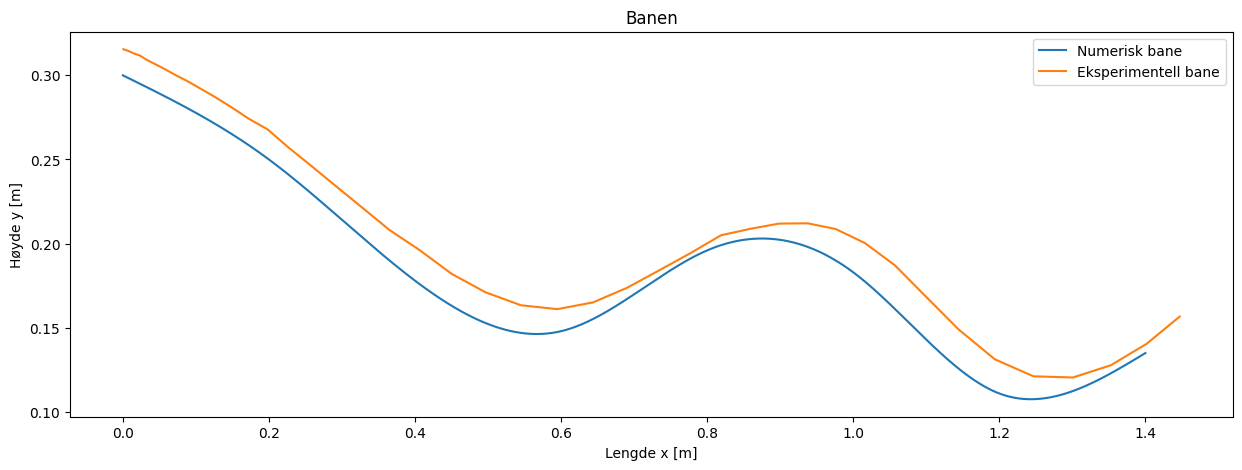

In [57]:
#Innlesing av eksperimentelle verdier for t, x og y
import pandas as pd
data=pd.read_csv("kule6.txt",sep=";")
t_exp=np.array(data["t"])
x_exp=np.array(data["x"])
y_exp=np.array(data["y"])

#Plotting av numerisk og eksperimentell bane
fig, ax1 = plt.subplots(1, figsize=(15, 5))

ax1.plot(x, y, label="Numerisk bane")
ax1.plot(x_exp, y_exp, label="Eksperimentell bane")

ax1.set_title("Banen")
ax1.set_ylabel("Høyde y [m]")
ax1.set_xlabel("Lengde x [m]")
ax1.legend()

plt.show()

## Numerisk vs eksperimentell hastighet

*I neste celle kan dere bruke numpyfunksjonen gradient til å beregne den eksperimentelle hastigheten til kula, både komponentene $v_x$ og $v_y$ og absoluttverdien $v = \sqrt{v_x^2+v_y^2}$. Tips:*
```python
vx_exp = np.gradient(x_exp,t_exp)
```
*På tilsvarende vis lages vy_exp, og deretter*
```python
v_exp = np.sqrt(vx_exp**2+vy_exp**2)
```
*Lag figurer som sammenligner numerisk og eksperimentell $v(x)$, $v(t)$ og $x(t)$. Disse tre figurene gir et godt inntrykk av samsvaret mellom teoretisk og eksperimentell bevegelse.*

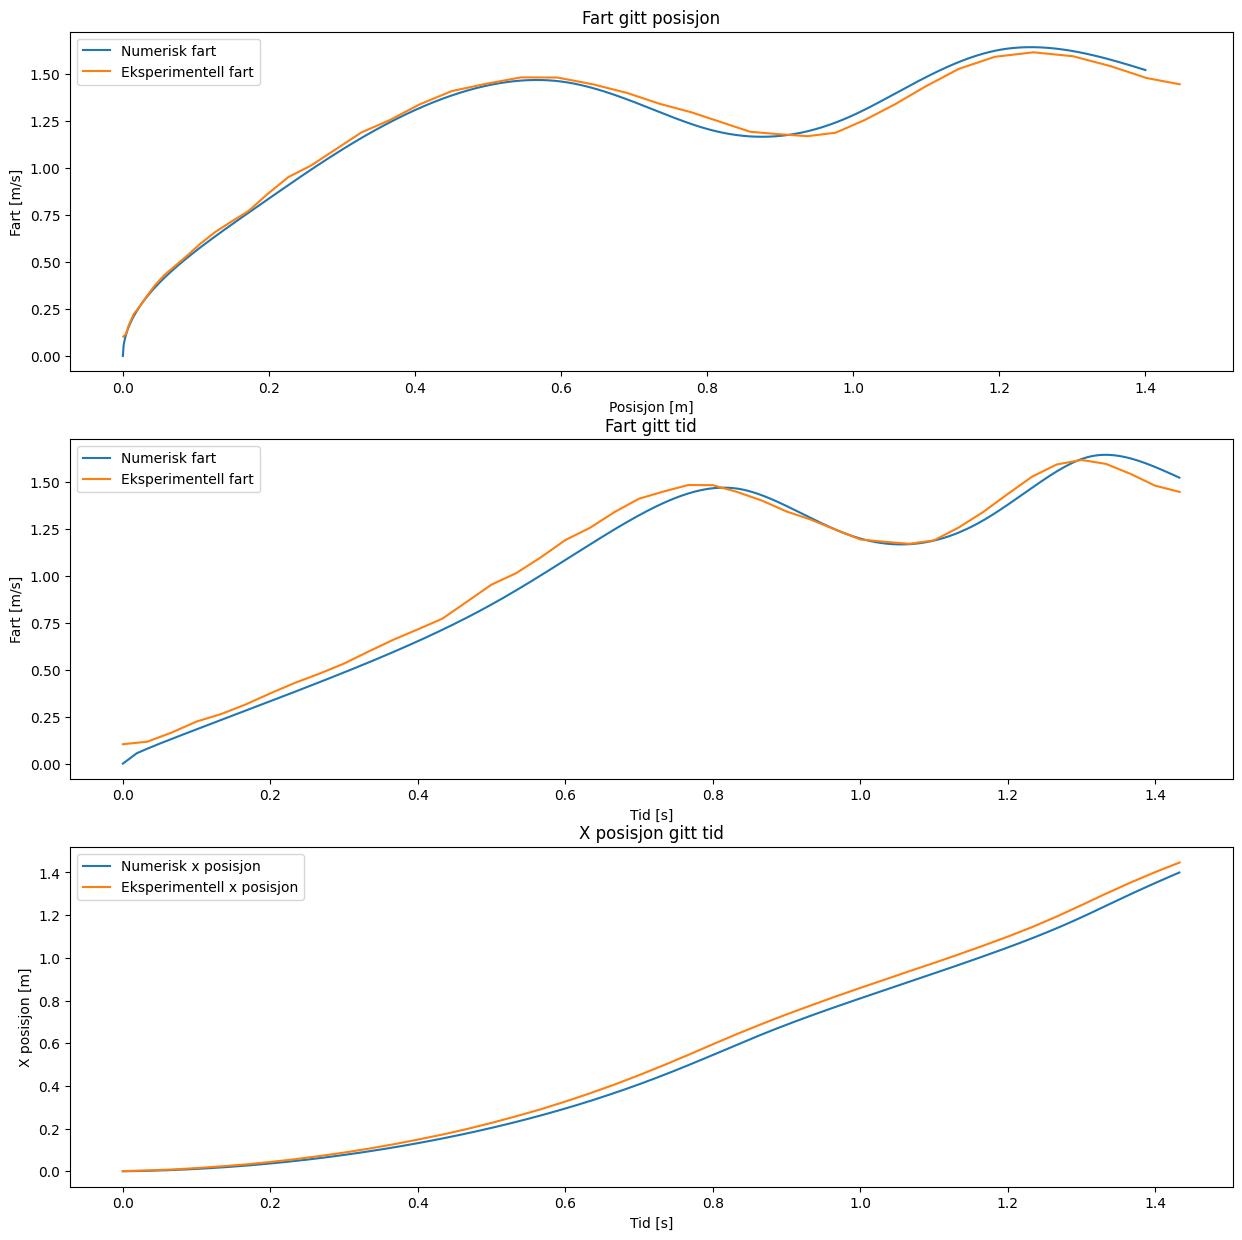

In [58]:
#Beregning av eksperimentell v_x, v_y og v
vx_exp = np.gradient(x_exp, t_exp)
vy_exp = np.gradient(y_exp, t_exp)

v_exp = np.sqrt(vx_exp**2+vy_exp**2)

#Figurer som sammenligner numerisk og eksperimentell v(x), v(t) og x(t)

#Plotting av numerisk og eksperimentell bane
fig, (ax1, ax2, ax3) = plt.subplots(3, figsize=(15, 15))

ax1.plot(x, v, label="Numerisk fart")
ax1.plot(x_exp, v_exp, label="Eksperimentell fart")

ax1.set_title("Fart gitt posisjon")
ax1.set_ylabel("Fart [m/s]")
ax1.set_xlabel("Posisjon [m]")
ax1.legend()

ax2.plot(t, v, label="Numerisk fart")
ax2.plot(t_exp, v_exp, label="Eksperimentell fart")

ax2.set_title("Fart gitt tid")
ax2.set_ylabel("Fart [m/s]")
ax2.set_xlabel("Tid [s]")
ax2.legend()

ax3.plot(t, x, label="Numerisk x posisjon")
ax3.plot(t_exp, x_exp, label="Eksperimentell x posisjon")

ax3.set_title("X posisjon gitt tid")
ax3.set_ylabel("X posisjon [m]")
ax3.set_xlabel("Tid [s]")
ax3.legend()

plt.show()

## Numeriske vs eksperimentelle mekaniske energier

*I neste celle beregner dere eksperimentelle mekaniske energier: Kinetisk energi (translasjonsenergi og rotasjonsenergi), potensiell energi og total mekanisk energi. Sammenlign numerisk og eksperimentell total mekanisk, kinetisk og potensiell energi i en og samme figur (i alt 6 kurver).*

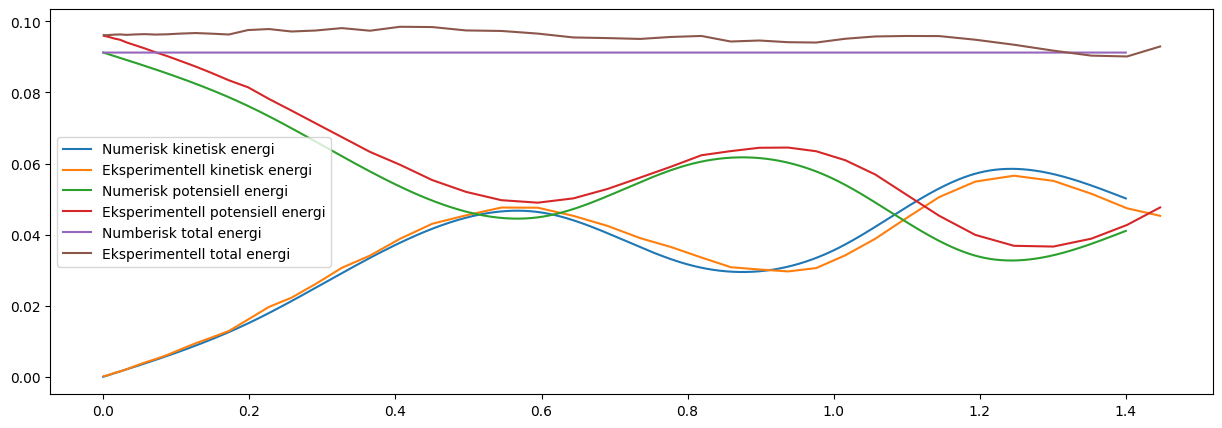

In [66]:
#Beregning av eksperimentell Etrans_exp, Erot_exp, Ekin_exp, Epot_exp, Etot_exp

Etrans_exp = 1 / 2 * M * v_exp ** 2
Erot_exp = c / 2 * M * v_exp ** 2
Ekin_exp = Etrans_exp + Erot_exp #(1 + c) / 2 * M * v_exp ** 2
Epot_exp = M * g * y_exp
Etot_exp = Ekin_exp + Epot_exp

#Figurer som sammenligner numerisk og eksperimentell kinetisk, potensiell og total mekanisk energi

fig, ax1 = plt.subplots(1, figsize=(15, 5))

ax1.plot(x, Ekin, label="Numerisk kinetisk energi")
ax1.plot(x_exp, Ekin_exp, label="Eksperimentell kinetisk energi")

ax1.plot(x, Epot, label="Numerisk potensiell energi")
ax1.plot(x_exp, Epot_exp, label="Eksperimentell potensiell energi")

ax1.plot(x, Etot, label="Numberisk total energi")
ax1.plot(x_exp, Etot_exp, label="Eksperimentell total energi")

ax1.legend()

plt.show()

## Er den mekaniske energien bevart i rulleforsøkene?
*Fordel de 8 rulleforsøkene på gruppas medlemmer. For hvert rulleforsøk: Bruk posisjons- og fartsdata i start- og sluttpunktet fra Tracker til å beregne total mekanisk energi $E_i$ i startposisjonen (ved $x=0$) og $E_f$ i sluttposisjonen (ved $x=1.40$ m). I neste celle: Skriv de 8 verdiene for $E_i$ og $E_f$ inn i numpy arrays. Beregn 8 verdier for $\Delta E = E_i-E_f$ og deretter midlere tap i mekanisk energi med usikkerhet (den såkalte standardfeilen). Skriv ut resultatet på formen $\Delta E = (2.5 \pm 0.4)$ mJ, med egne tallverdier selvsagt. En passende enhet for $\Delta E$ er trolig mJ.*

In [70]:
#Beregning av Delta E = E_i - E_f for 8 vellykkede rulleforsøk

E_i = np.zeros(8)
E_f = np.zeros(8)

for i in range(8):
    filename = f"kule{i + 1}.txt"

    data = pd.read_csv(filename,sep=";")
    t_it = np.array(data["t"])
    x_it = np.array(data["x"])
    y_it = np.array(data["y"])

    vx_it = np.gradient(x_it, t_it)
    vy_it = np.gradient(y_it, t_it)
    v_it = np.sqrt(vx_it**2+vy_it**2)

    Ekin_it = (1 + c) / 2 * M * v_it ** 2
    Epot_it = M * g * y_it
    Etot_it = Ekin_it + Epot_it

    E_i[i] = Etot_it[0]
    E_f[i] = Etot_it[-1]

E_delta = E_i - E_f

print(E_i)
print(E_f)
print(E_delta)
    
#Beregning av middelverdi og standardfeil for Delta E

middelverdi = E_delta.mean()
print(middelverdi)

stdavvik = np.std(E_delta)
print(stdavvik)

#Utskrift av Delta E på formen Delta E = (Middelverdi +- Standardfeil) mJ


[0.09862688 0.09866378 0.09522107 0.09813754 0.098244   0.09617782
 0.09837379 0.10018712]
[0.09235984 0.09436964 0.09317838 0.09511151 0.0961067  0.09294735
 0.09333258 0.09781106]
[0.00626704 0.00429413 0.00204269 0.00302604 0.00213731 0.00323047
 0.00504121 0.00237606]
0.0035518675517496844
0.0014222415379581059


## Noen avsluttende spørsmål
*Første spørsmål tar utgangspunkt i de eksperimentelle resultatene:*
- Er beregnet middelverdi og usikkerhet for tapt mekanisk energi i samsvar med antagelsen om at kula ruller rent uten å gli? I motsatt fall: Diskuter kort noen faktorer som kan bidra til at mekanisk energi går tapt i rulleforsøkene. <br>

*De neste spørsmålene tar utgangspunkt i de teoretiske (numeriske) resultatene:* <br>
- Er grafen for $f(x)$ rimelig, med utgangspunkt i baneformen $y(x)$? Vurder spesielt topp- og bunnpunktene, samt fortegnet på $f(x)$ underveis.
- Er grafen for $N(x)$ rimelig, med utgangspunkt i baneformen $y(x)$? Vurder spesielt om $N$ har stor verdi på forventede steder.
- Maksimal statisk friksjonskraft er som kjent bestemt av $\mu_s N$. Hva må den statiske friksjonskoeffisienten $\mu_s$ mellom kule og bane minst være for at kula hele veien skal rulle rent uten å gli? Grafen for $|f(x)/N(x)|$ gir grunnlag for å svare på dette.
- Grafen for banens krumning $K(x)$ er kontinuerlig (sammenhengende), med tydelige knekkpunkter for hver 20. cm. Er dette som forventet? Forklar.
- I det teoretiske grunnlaget er det antatt at kulas radius er liten sammenlignet med banens krumningsradius. Er denne antagelsen i orden langs hele banen? Sammenlign kuleradien med banens minste krumningsradius.